# Extensions

Six extensions to the main experiment (`Main_Experiment.ipynb`). The data
come from `python -m utils.extensions` (see the docstring of
`utils/extensions.py`):

| File | Extension |
|---|---|
| `data/ext_fine_sweep.csv`, `data/ext_wait_samples.npz` | 1 tipping point, 2 self-organised timing, 3 distributions: arrival rate 0.02 to 0.30 in steps of 0.01, north–south share 0.5 and 0.9, right-turn share 0.3, reaction delay 0 and 0.2, 10 seeds, all three controllers |
| `data/ext_sensing.csv` | 4 limited sensing |
| `data/ext_drivers.csv` | 5 different drivers |
| `data/ext_surge.npz` | 6 time-varying demand |

Figures are saved to `figures/` with names starting `ext_`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

CONTROLLERS = ["fixed", "webster", "adaptive"]
LABELS = {"fixed": "Fixed-time (untuned)", "webster": "Fixed-time (Webster)", "adaptive": "Adaptive"}
COLOURS = {"fixed": "C0", "webster": "C2", "adaptive": "C1"}
DELAY_STYLE = {0.0: "-", 0.2: "--"}

fine = pd.read_csv(ROOT / "data" / "ext_fine_sweep.csv")
fine["turned_away"] = fine["blocked_arrivals"] / (400 * fine["arrival_rate"])
fine["ns_green_share"] = (fine["green_share_1"] + fine["green_share_2"]) / fine[
    ["green_share_1", "green_share_2", "green_share_3", "green_share_4"]].sum(axis=1)
fine["design_ns_share"] = (fine["design_share_1"] + fine["design_share_2"]) / fine[
    ["design_share_1", "design_share_2", "design_share_3", "design_share_4"]].sum(axis=1)
fine["all_red_share"] = 1 - fine[["green_share_1", "green_share_2", "green_share_3", "green_share_4"]].sum(axis=1)
SETTINGS = ["controller", "north_south_share", "reaction_delay", "arrival_rate"]
means = fine.groupby(SETTINGS).mean(numeric_only=True).reset_index()
print(len(fine), "runs in the fine sweep")


def lines(ax, value, share, controllers=CONTROLLERS, delays=(0.0, 0.2), scale=1, label_delay=True):
    # One line per controller and reaction delay, averaged over seeds.
    for controller in controllers:
        for delay in delays:
            data = means[(means["controller"] == controller) & (means["north_south_share"] == share)
                         & (means["reaction_delay"] == delay)]
            label = LABELS[controller] + (f", delay {delay}" if label_delay else "")
            ax.plot(data["arrival_rate"], scale * data[value], DELAY_STYLE[delay],
                    color=COLOURS[controller], label=label)

3480 runs in the fine sweep


## 1. Tipping point

As the arrival rate rises past what a controller can serve, the intersection
changes abruptly from free-flowing (short queues that clear every cycle) to
congested (queues filling the approaches). Three signs of such a transition
are measured in every run:

* the **mean number of cars on the approaches**, which jumps at the transition;
* **fluctuations**: the standard deviation of that number over the measured
  window, which peaks near the transition, because queues neither clear
  reliably nor stay full;
* **critical slowing down**: the settling time, the number of steps from an
  empty start until the number of cars first reaches 90% of its level in the
  measured window, which is longest near the transition.

The critical arrival rate of each controller is taken as the rate at which
the fluctuations peak. Solid lines: no reaction delay; dashed: delay 0.2.

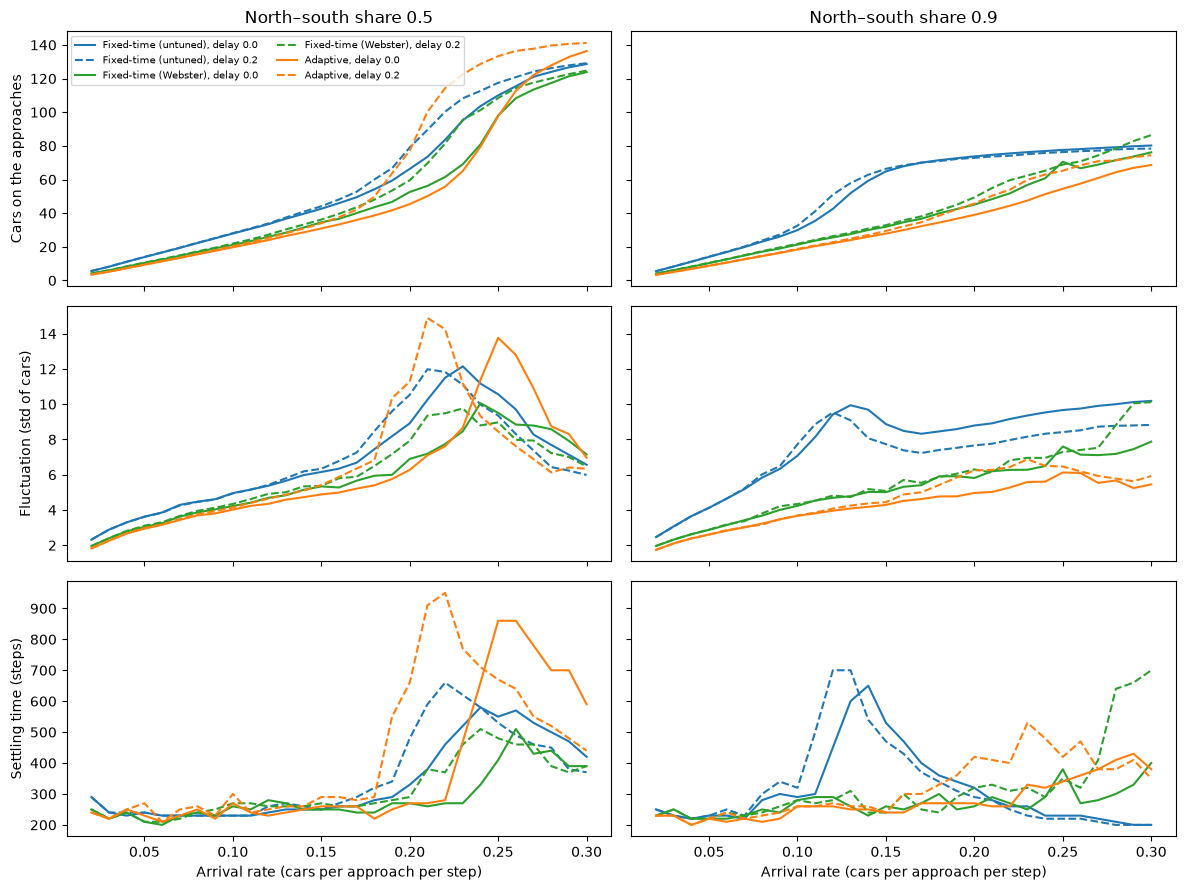

Critical arrival rate (where fluctuations peak; NaN = no peak within the sweep)
controller                        fixed  webster  adaptive
north_south_share reaction_delay                          
0.5               0.0              0.23     0.24      0.25
                  0.2              0.21     0.23      0.21
0.9               0.0               NaN      NaN      0.25
                  0.2              0.12      NaN      0.23


In [2]:
shares = sorted(fine["north_south_share"].unique())
rows = [("cars_mean", "Cars on the approaches"), ("cars_std", "Fluctuation (std of cars)"),
        ("settling_time", "Settling time (steps)")]
fig, axes = plt.subplots(len(rows), len(shares), figsize=(12, 9), sharex=True, sharey="row")
for col, share in enumerate(shares):
    for row, (value, label) in enumerate(rows):
        lines(axes[row, col], value, share)
        axes[row, 0].set_ylabel(label)
    axes[0, col].set_title(f"North–south share {share}")
    axes[-1, col].set_xlabel("Arrival rate (cars per approach per step)")
axes[0, 0].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "ext_tipping.png", dpi=200)
plt.show()

peaks = means.loc[means.groupby(["controller", "north_south_share", "reaction_delay"])["cars_std"].idxmax()]
peaks = peaks.set_index(["controller", "north_south_share", "reaction_delay"])["arrival_rate"]
critical = peaks.where(peaks < means["arrival_rate"].max()).unstack("controller")   # a peak at the edge is no peak
print("Critical arrival rate (where fluctuations peak; NaN = no peak within the sweep)")
print(critical[CONTROLLERS])

## 2. Self-organised timing

Webster's method designs a cycle length and a split of green time from the
average demand. The adaptive controller has no plan: the length of its greens,
how the green time is split between directions and the time between two
greens of the same phase (its effective cycle) all emerge from the waiting
cars. Does local feedback find the designed timing by itself?

Left: average length of a green. Middle: north–south share of the green
time. Right: share of time spent in all-red, the time lost to switching.
Colours are controllers; circles are north–south share 0.5 and squares 0.9;
dashed lines have reaction delay 0.2.

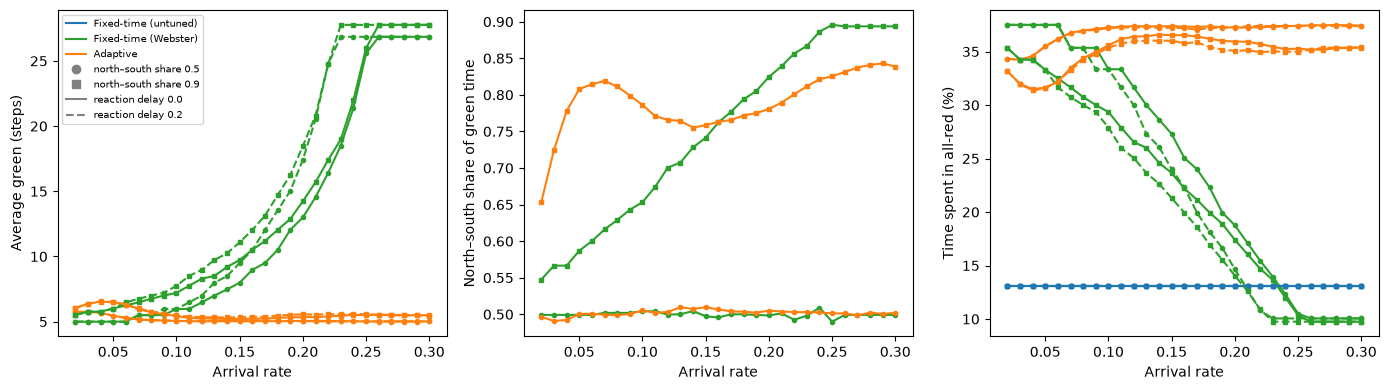

                               mean_green            cycle design_cycle  \
controller                       adaptive webster adaptive      webster   
north_south_share arrival_rate                                            
0.5               0.05               5.46    5.00    35.22         32.0   
                  0.10               5.05    5.98    33.50         36.0   
                  0.15               5.03    7.99    33.34         44.0   
                  0.20               5.05   13.00    33.76         64.0   
                  0.25               5.01   25.57    34.15        114.0   
0.9               0.05               6.49    6.01    61.01         36.0   
                  0.10               5.42    7.21    50.31         41.0   
                  0.15               5.21    9.73    45.56         51.0   
                  0.20               5.35   14.24    48.16         69.0   
                  0.25               5.50   25.99    57.58        116.0   

                        

In [3]:
means["mean_green"] = 100 * (1 - means["all_red_share"]) / means["phase_changes"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for share, marker in [(0.5, "o"), (0.9, "s")]:
    for delay in (0.0, 0.2):
        data = means[(means["north_south_share"] == share) & (means["reaction_delay"] == delay)]
        style = dict(linestyle=DELAY_STYLE[delay], marker=marker, markersize=3)
        for controller in ["webster", "adaptive"]:
            runs = data[data["controller"] == controller]
            axes[0].plot(runs["arrival_rate"], runs["mean_green"], color=COLOURS[controller], **style)
            if delay == 0.0:
                axes[1].plot(runs["arrival_rate"], runs["ns_green_share"], color=COLOURS[controller], **style)
        for controller in CONTROLLERS:
            runs = data[data["controller"] == controller]
            axes[2].plot(runs["arrival_rate"], 100 * runs["all_red_share"], color=COLOURS[controller], **style)
axes[0].set_ylabel("Average green (steps)")
axes[1].set_ylabel("North–south share of green time")
axes[2].set_ylabel("Time spent in all-red (%)")
handles = ([plt.Line2D([], [], color=COLOURS[c], label=LABELS[c]) for c in CONTROLLERS]
           + [plt.Line2D([], [], color="grey", marker=m, linestyle="", label=f"north–south share {s}")
              for s, m in [(0.5, "o"), (0.9, "s")]]
           + [plt.Line2D([], [], color="grey", linestyle=DELAY_STYLE[d], label=f"reaction delay {d}")
              for d in (0.0, 0.2)])
axes[0].legend(handles=handles, fontsize=7)
for ax in axes:
    ax.set_xlabel("Arrival rate")
fig.tight_layout()
fig.savefig(FIGURES / "ext_timing.png", dpi=200)
plt.show()

table = means[(means["reaction_delay"] == 0.0) & means["arrival_rate"].isin([0.05, 0.1, 0.15, 0.2, 0.25])]
print(table.pivot_table(index=["north_south_share", "arrival_rate"], columns="controller",
                        values=["mean_green", "cycle", "design_cycle", "ns_green_share", "all_red_share"]).round(2)
      [[("mean_green", "adaptive"), ("mean_green", "webster"), ("cycle", "adaptive"), ("design_cycle", "webster"),
        ("ns_green_share", "adaptive"), ("ns_green_share", "webster"),
        ("all_red_share", "adaptive"), ("all_red_share", "webster")]])

## 3. Distributions of waiting time

Means can hide a few cars waiting a very long time. Left: median, 90th and
99th percentile of individual waits (north–south share 0.9, no reaction
delay). Right: the share of cars waiting longer than a given time at arrival
rate 0.15, from the pooled waits of all ten seeds.

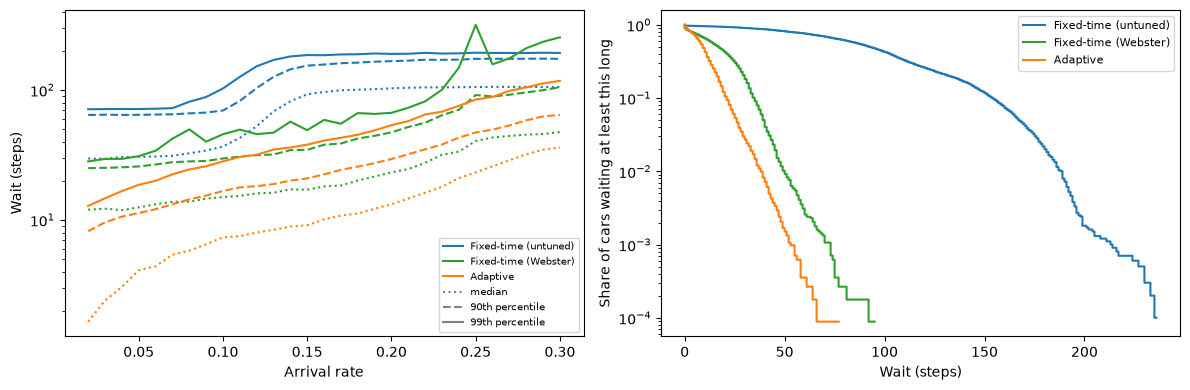

             mean_wait                wait_max                wait_p50         \
controller    adaptive  fixed webster adaptive  fixed webster adaptive  fixed   
arrival_rate                                                                    
0.05               4.9   31.3    12.8     23.9   72.3    39.5      4.1   30.6   
0.10               8.0   37.5    15.4     41.2  125.7    66.3      7.4   36.8   
0.15              10.5   92.6    17.7     56.5  211.1    71.8      9.1   92.7   
0.20              15.2  103.4    23.9    100.9  218.0   103.3     13.2  102.9   

                     wait_p90  ...         wait_p90_ew                \
controller   webster adaptive  ... webster    adaptive fixed webster   
arrival_rate                   ...                                     
0.05            12.5     11.3  ...    25.8        16.7  61.5    27.0   
0.10            15.0     16.7  ...    29.7        26.6  61.9    32.3   
0.15            17.1     20.9  ...    34.6        36.3  62.9    41.0   


In [4]:
samples = np.load(ROOT / "data" / "ext_wait_samples.npz")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data = means[(means["north_south_share"] == 0.9) & (means["reaction_delay"] == 0.0)]
for controller in CONTROLLERS:
    runs = data[data["controller"] == controller]
    for value, style in [("wait_p50", ":"), ("wait_p90", "--"), ("wait_p99", "-")]:
        axes[0].plot(runs["arrival_rate"], runs[value], style, color=COLOURS[controller])
for controller in CONTROLLERS:
    axes[0].plot([], [], color=COLOURS[controller], label=LABELS[controller])
for value, style in [("median", ":"), ("90th percentile", "--"), ("99th percentile", "-")]:
    axes[0].plot([], [], style, color="grey", label=value)
axes[0].set_yscale("log")
axes[0].set_xlabel("Arrival rate")
axes[0].set_ylabel("Wait (steps)")
axes[0].legend(fontsize=7)
for controller in CONTROLLERS:
    waits = np.sort(samples[f"{controller}_0.15_0.9_0.0"])
    survival = 1 - np.arange(len(waits)) / len(waits)
    axes[1].step(waits, survival, color=COLOURS[controller], label=LABELS[controller])
axes[1].set_yscale("log")
axes[1].set_xlabel("Wait (steps)")
axes[1].set_ylabel("Share of cars waiting at least this long")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ext_distributions.png", dpi=200)
plt.show()

print(data[data["arrival_rate"].isin([0.05, 0.1, 0.15, 0.2])].pivot_table(
    index="arrival_rate", columns="controller",
    values=["mean_wait", "wait_p50", "wait_p90", "wait_p99", "wait_max", "wait_p90_ns", "wait_p90_ew"]).round(1))

## 4. Limited sensing

In the main experiment the adaptive controller knows the waiting time of
every car in every pocket. Here it sees only the cells nearest the stop line:
0 cells means no information at all (every green lasts the minimum 5 steps),
1 cell is a single detector at the stop line, 10 cells is the whole pocket.
Dashed lines show Webster's plan in the same conditions (from the fine
sweep).

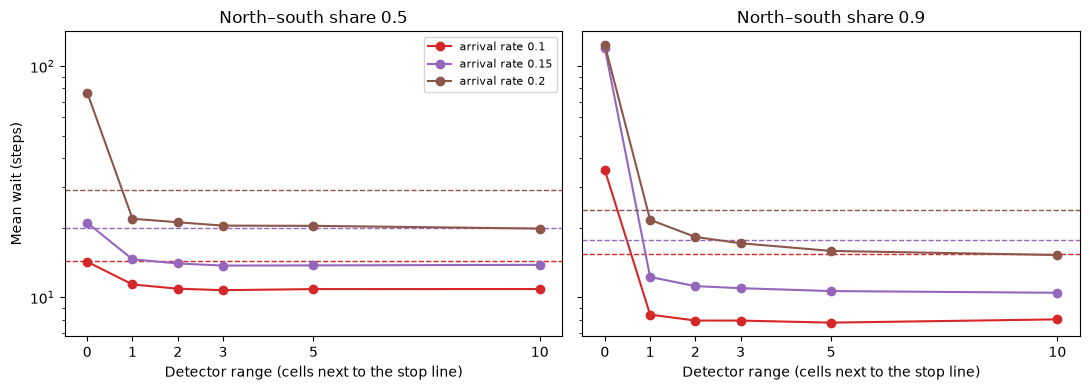

detector_range                     0     1     2     3     5     10
north_south_share arrival_rate                                     
0.5               0.10           14.2  11.4  10.9  10.7  10.8  10.9
                  0.15           21.0  14.6  14.0  13.7  13.7  13.8
                  0.20           76.8  21.9  21.1  20.4  20.4  19.8
0.9               0.10           35.5   8.4   7.9   7.9   7.8   8.0
                  0.15          119.4  12.2  11.2  10.9  10.6  10.5
                  0.20          123.1  21.6  18.2  17.1  15.9  15.2


In [5]:
sensing = pd.read_csv(ROOT / "data" / "ext_sensing.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, share in zip(axes, sorted(sensing["north_south_share"].unique())):
    for i, rate in enumerate(sorted(sensing["arrival_rate"].unique())):
        runs = sensing[(sensing["north_south_share"] == share) & (sensing["arrival_rate"] == rate)]
        mean = runs.groupby("detector_range")["mean_wait"].mean()
        ax.plot(mean.index, mean, marker="o", color=f"C{i + 3}", label=f"arrival rate {rate}")
        webster = fine[(fine["controller"] == "webster") & (fine["north_south_share"] == share)
                       & (fine["reaction_delay"] == 0.0) & np.isclose(fine["arrival_rate"], rate)]["mean_wait"].mean()
        ax.axhline(webster, linestyle="--", color=f"C{i + 3}", linewidth=1)
    ax.set_yscale("log")
    ax.set_xticks(sorted(sensing["detector_range"].unique()))
    ax.set_xlabel("Detector range (cells next to the stop line)")
    ax.set_title(f"North–south share {share}")
axes[0].set_ylabel("Mean wait (steps)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ext_sensing.png", dpi=200)
plt.show()

print(sensing.pivot_table(index=["north_south_share", "arrival_rate"], columns="detector_range",
                          values="mean_wait").round(1))

## 5. Different drivers

The main experiment gives every driver the same chance of stalling. Here the
same average delay is concentrated in fewer drivers: with slow-driver share
0.25, a quarter of drivers stall with four times the probability and the rest
never stall. A slow driver at the front of a queue holds up everyone behind,
and the expected stalled time of a driver, $\delta/(1-\delta)$, grows faster
than $\delta$, so concentrating the delay should cost more than spreading it.
Webster's plan is still designed for the average delay.

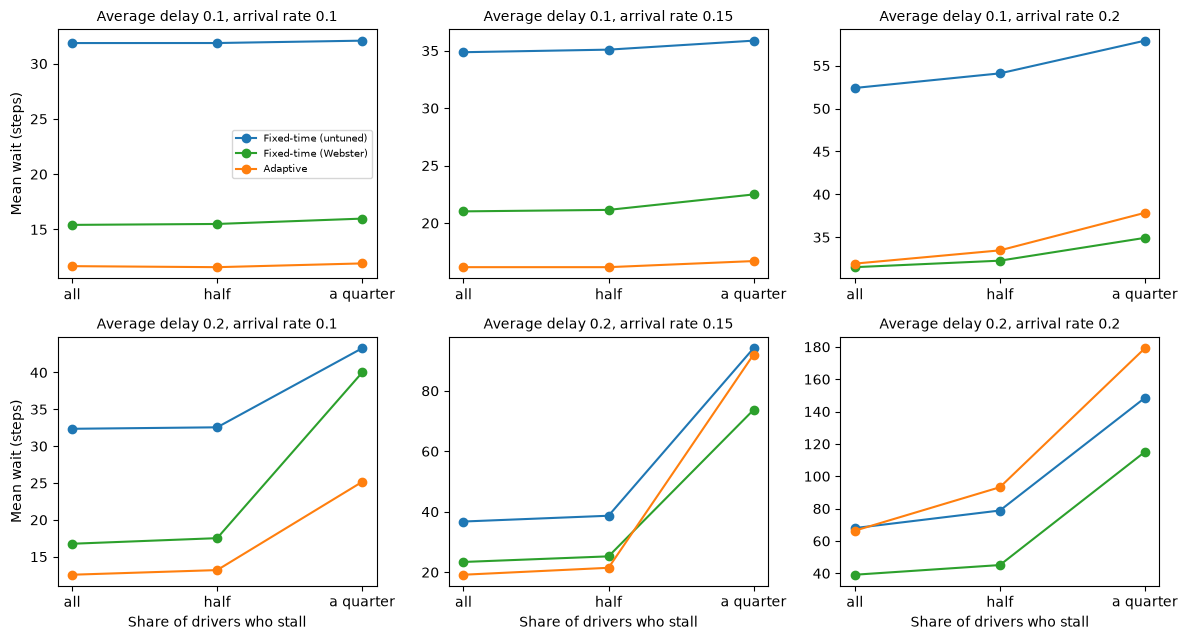

                                              mean_wait                 \
controller                                     adaptive  fixed webster   
reaction_delay arrival_rate slow_driver_share                            
0.1            0.10         0.25                   11.9   32.1    16.0   
                            0.50                   11.6   31.9    15.5   
                            1.00                   11.7   31.9    15.4   
               0.15         0.25                   16.7   35.9    22.5   
                            0.50                   16.2   35.1    21.1   
                            1.00                   16.2   34.9    21.0   
               0.20         0.25                   37.9   57.9    34.9   
                            0.50                   33.5   54.1    32.3   
                            1.00                   31.9   52.4    31.5   
0.2            0.10         0.25                   25.2   43.3    40.0   
                            0.50      

In [6]:
drivers = pd.read_csv(ROOT / "data" / "ext_drivers.csv")
delays = sorted(drivers["reaction_delay"].unique())
rates = sorted(drivers["arrival_rate"].unique())
slow_shares = [1.0, 0.5, 0.25]                     # from all drivers alike to a few very slow ones
fig, axes = plt.subplots(len(delays), len(rates), figsize=(12, 6.5))
for row, delay in enumerate(delays):
    for col, rate in enumerate(rates):
        ax = axes[row, col]
        for controller in CONTROLLERS:
            runs = drivers[(drivers["controller"] == controller) & (drivers["reaction_delay"] == delay)
                           & (drivers["arrival_rate"] == rate)]
            mean = runs.groupby("slow_driver_share")["mean_wait"].mean()
            ax.plot(range(len(slow_shares)), mean[slow_shares], marker="o", color=COLOURS[controller],
                    label=LABELS[controller])
        ax.set_title(f"Average delay {delay}, arrival rate {rate}", fontsize=10)
        ax.set_xticks(range(len(slow_shares)), ["all", "half", "a quarter"])
    axes[row, 0].set_ylabel("Mean wait (steps)")
for ax in axes[-1]:
    ax.set_xlabel("Share of drivers who stall")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "ext_drivers.png", dpi=200)
plt.show()

print(drivers.pivot_table(index=["reaction_delay", "arrival_rate", "slow_driver_share"],
                          columns="controller", values=["mean_wait", "stalls"]).round(1))

## 6. Time-varying demand

The arrival rate is steady at 0.1, rises linearly to 0.25 (beyond every
controller's capacity) over 500 steps, falls back over the next 500 and stays
at 0.1 while the queues clear. Webster's plan is designed for the normal
demand of 0.1, as a plan made for typical traffic would be. Curves are
averages of 20 seeds with 70% of traffic from the north and south. Left: cars
on the approaches over time (grey: arrival rate, right axis). Right: cars
against the current arrival rate while demand rises (solid) and falls
(dashed); the gap between the two is hysteresis, congestion persisting after
its cause has passed. The table also gives the extra car-steps caused by the
surge (cars above their level before it, summed over the rest of the run).

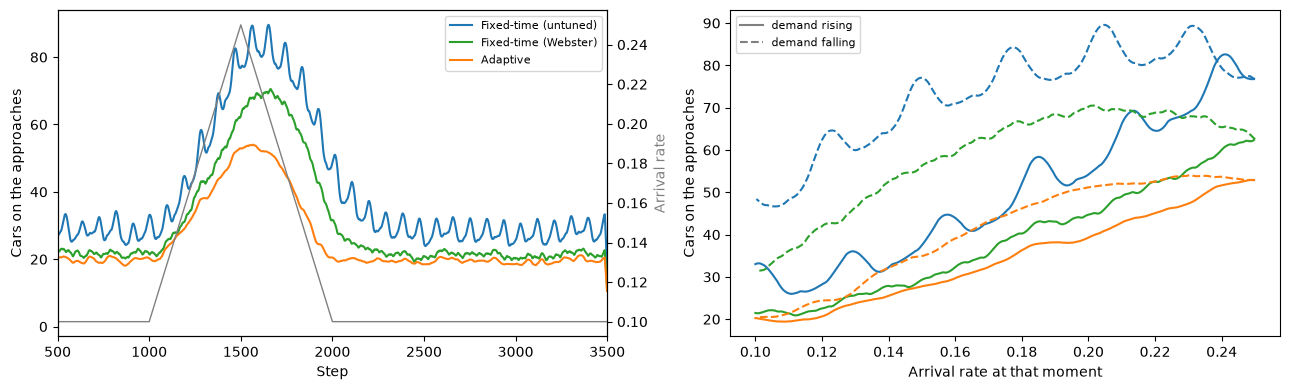

              cars before  peak cars  peak at step  \
0.5 fixed            27.8       84.0        1559.0   
    webster          21.2       65.8        1589.0   
    adaptive         19.8       59.2        1586.0   
0.7 fixed            28.4       95.6        1651.0   
    webster          21.8       73.4        1662.0   
    adaptive         19.8       54.6        1565.0   

              recovery after surge (steps)  extra car-steps  \
0.5 fixed                             26.0          27532.0   
    webster                           31.0          22068.0   
    adaptive                           0.0          19218.0   
0.7 fixed                            201.0          34928.0   
    webster                          124.0          27080.0   
    adaptive                           0.0          17545.0   

              turned away in surge  
0.5 fixed                     26.8  
    webster                   25.0  
    adaptive                  24.9  
0.7 fixed                     6

In [7]:
surge = np.load(ROOT / "data" / "ext_surge.npz")
demand = surge["demand"]
steps = np.arange(len(demand))
rise = (steps >= 1000) & (steps < 1500)
fall = (steps >= 1500) & (steps < 2000)


def smooth(x, n=25):
    return np.convolve(x, np.ones(n) / n, mode="same")


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for controller in CONTROLLERS:
    cars = surge[f"cars_{controller}_0.7"]
    axes[0].plot(steps, smooth(cars), color=COLOURS[controller], label=LABELS[controller])
    axes[1].plot(demand[rise], smooth(cars)[rise], color=COLOURS[controller], label=LABELS[controller])
    axes[1].plot(demand[fall], smooth(cars)[fall], "--", color=COLOURS[controller])
twin = axes[0].twinx()
twin.plot(steps, demand, color="grey", linewidth=1)
twin.set_ylabel("Arrival rate", color="grey")
axes[0].set_xlim(500, 3500)
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Cars on the approaches")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].set_xlabel("Arrival rate at that moment")
axes[1].set_ylabel("Cars on the approaches")
axes[1].legend(handles=[plt.Line2D([], [], color="grey", label="demand rising"),
                        plt.Line2D([], [], color="grey", linestyle="--", label="demand falling")],
               fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "ext_surge.png", dpi=200)
plt.show()

# Recovery: steps after demand is back to normal (step 2000) until the 50-step
# average of cars on the road is within 10% of its level before the surge.
summary = {}
for share in (0.5, 0.7):
    for controller in CONTROLLERS:
        cars = surge[f"cars_{controller}_{share}"]
        before = cars[500:1000].mean()
        average = np.convolve(cars, np.ones(50) / 50, mode="valid")    # average[t] = mean of cars[t:t+50]
        back = np.flatnonzero(average[2000:] <= 1.1 * before)
        turned = surge[f"turned_away_{controller}_{share}"]
        summary[(share, controller)] = {
            "cars before": round(before, 1), "peak cars": round(cars.max(), 1),
            "peak at step": int(np.argmax(smooth(cars))),
            "recovery after surge (steps)": int(back[0]) if len(back) else None,
            "extra car-steps": int((cars[1000:] - before).sum()),
            "turned away in surge": round(turned[2000] - turned[1000], 1)}
print(pd.DataFrame(summary).T)